In [35]:
import pandas as pd
import matplotlib.pyplot as plt

In [44]:
df = pd.read_parquet("data/nber_papers.parquet")

In [45]:
# Create a boolean mask for records mentioning "artificial intelligence" or "AI" in the Abstract
ai_mask = df['Abstract'].str.contains(r'\b(artificial intelligence|AI)\b', case=False, na=False, regex=True)

# Group by Date and calculate count and percent
ai_by_date = df.groupby('Date').agg(
    total_count=('Abstract', 'size'),
    ai_count=('Abstract', lambda x: ai_mask[x.index].sum())
)

ai_by_date['ai_percent'] = (ai_by_date['ai_count'] / ai_by_date['total_count'] * 100).round(2)

ai_by_date.index = pd.to_datetime(ai_by_date.index)
ai_by_date = ai_by_date.sort_index()

# Convert Date to datetime and extract quarter-year
ai_by_date_quarterly = ai_by_date.copy()
ai_by_date_quarterly['Quarter'] = ai_by_date_quarterly.index.to_period('Q')

# Group by quarter and sum the counts
ai_quarterly = ai_by_date_quarterly.groupby('Quarter').agg(
    total_count=('total_count', 'sum'),
    ai_count=('ai_count', 'sum')
)

# Recalculate percentage
ai_quarterly['ai_percent'] = (ai_quarterly['ai_count'] / ai_quarterly['total_count'] * 100).round(2)

# Make counts cumulative
ai_quarterly['cumulative_total_count'] = ai_quarterly['total_count'].cumsum()
ai_quarterly['cumulative_ai_count'] = ai_quarterly['ai_count'].cumsum()
ai_quarterly['cumulative_ai_percent'] = (ai_quarterly['cumulative_ai_count'] / ai_quarterly['cumulative_total_count'] * 100).round(2)

print(ai_quarterly)

         total_count  ai_count  ai_percent  cumulative_total_count  \
Quarter                                                              
2020Q1           222         0        0.00                     222   
2020Q2           540         3        0.56                     762   
2020Q3           421         1        0.24                    1183   
2020Q4           437         3        0.69                    1620   
2021Q1           314         1        0.32                    1934   
2021Q2           348         3        0.86                    2282   
2021Q3           340         3        0.88                    2622   
2021Q4           309         3        0.97                    2931   
2022Q1           264         0        0.00                    3195   
2022Q2           297         6        2.02                    3492   
2022Q3           337         0        0.00                    3829   
2022Q4           287         6        2.09                    4116   
2023Q1           281

C:\Users\ohd90\AppData\Local\Temp\ipykernel_19256\1732724453.py:2: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  ai_mask = df['Abstract'].str.contains(r'\b(artificial intelligence|AI)\b', case=False, na=False, regex=True)
C:\Users\ohd90\AppData\Local\Temp\ipykernel_19256\1732724453.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ai_by_date.index = pd.to_datetime(ai_by_date.index)


In [46]:
# Create a boolean mask for records mentioning both "task" and ("artificial intelligence" or "AI") in the Abstract
task_mask = df['Abstract'].str.contains(r'\b(artificial intelligence|AI)\b.*\btask|\btask.*\b(artificial intelligence|AI)\b', case=False, na=False, regex=True)

# Group by Date and calculate count and percent
task_by_date = df.groupby('Date').agg(
    total_count=('Abstract', 'size'),
    task_count=('Abstract', lambda x: task_mask[x.index].sum())
)

task_by_date['task_percent'] = (task_by_date['task_count'] / task_by_date['total_count'] * 100).round(2)

task_by_date.index = pd.to_datetime(task_by_date.index)
task_by_date = task_by_date.sort_index()

# Convert Date to datetime and extract quarter-year
task_by_date_quarterly = task_by_date.copy()
task_by_date_quarterly['Quarter'] = task_by_date_quarterly.index.to_period('Q')

# Group by quarter and sum the counts
task_quarterly = task_by_date_quarterly.groupby('Quarter').agg(
    total_count=('total_count', 'sum'),
    task_count=('task_count', 'sum')
)

# Recalculate percentage
task_quarterly['task_percent'] = (task_quarterly['task_count'] / task_quarterly['total_count'] * 100).round(2)

# Make counts cumulative
task_quarterly['cumulative_total_count'] = task_quarterly['total_count'].cumsum()
task_quarterly['cumulative_task_count'] = task_quarterly['task_count'].cumsum()
task_quarterly['cumulative_task_percent'] = (task_quarterly['cumulative_task_count'] / task_quarterly['cumulative_total_count'] * 100).round(2)

print(task_quarterly)

         total_count  task_count  task_percent  cumulative_total_count  \
Quarter                                                                  
2020Q1           222           0          0.00                     222   
2020Q2           540           0          0.00                     762   
2020Q3           421           0          0.00                    1183   
2020Q4           437           1          0.23                    1620   
2021Q1           314           0          0.00                    1934   
2021Q2           348           1          0.29                    2282   
2021Q3           340           0          0.00                    2622   
2021Q4           309           0          0.00                    2931   
2022Q1           264           0          0.00                    3195   
2022Q2           297           2          0.67                    3492   
2022Q3           337           0          0.00                    3829   
2022Q4           287           1      

C:\Users\ohd90\AppData\Local\Temp\ipykernel_19256\665234937.py:2: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  task_mask = df['Abstract'].str.contains(r'\b(artificial intelligence|AI)\b.*\btask|\btask.*\b(artificial intelligence|AI)\b', case=False, na=False, regex=True)
C:\Users\ohd90\AppData\Local\Temp\ipykernel_19256\665234937.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  task_by_date.index = pd.to_datetime(task_by_date.index)


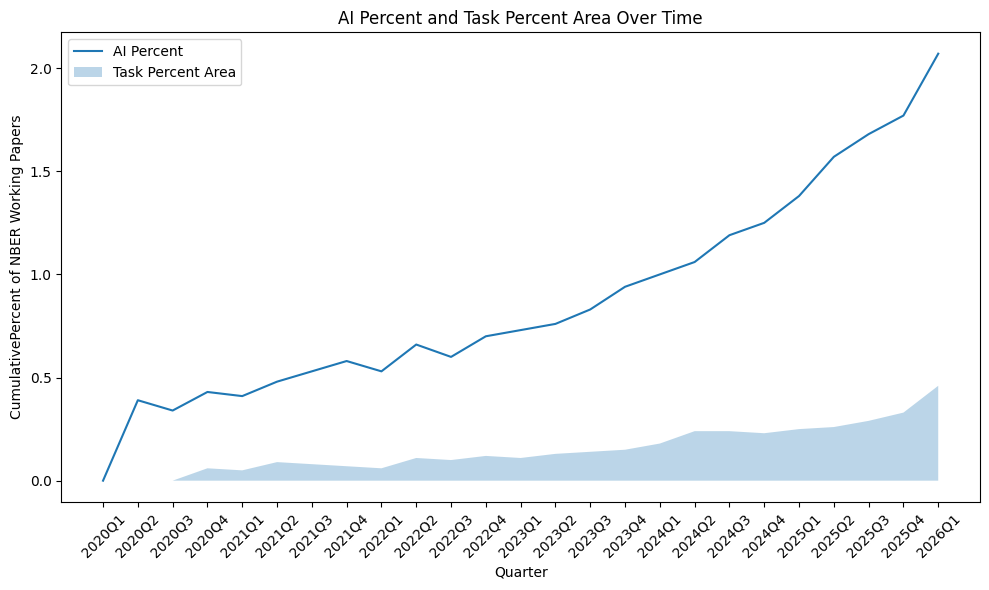

In [47]:
plt.figure(figsize=(10, 6))
plt.plot(ai_quarterly.index.astype(str), ai_quarterly['cumulative_ai_percent'], label='AI Percent')
plt.fill_between(task_quarterly.index.astype(str), task_quarterly['cumulative_task_percent'], alpha=0.3, label='Task Percent Area')
plt.title('AI Percent and Task Percent Area Over Time')
plt.xlabel('Quarter')
plt.ylabel('CumulativePercent of NBER Working Papers')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

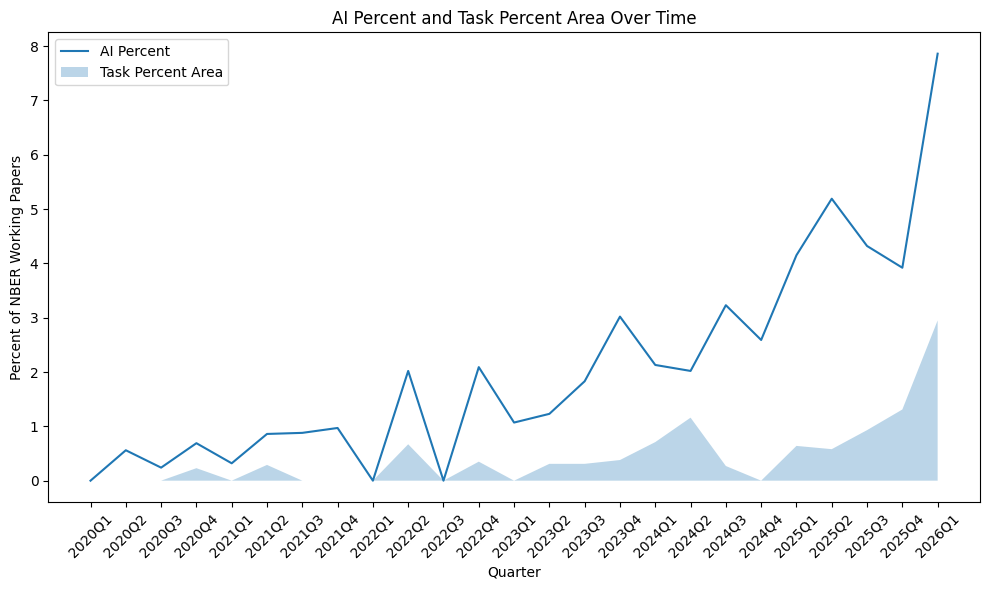

In [48]:
plt.figure(figsize=(10, 6))
plt.plot(ai_quarterly.index.astype(str), ai_quarterly['ai_percent'], label='AI Percent')
plt.fill_between(task_quarterly.index.astype(str), task_quarterly['task_percent'], alpha=0.3, label='Task Percent Area')
plt.title('AI Percent and Task Percent Area Over Time')
plt.xlabel('Quarter')
plt.ylabel('Percent of NBER Working Papers')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

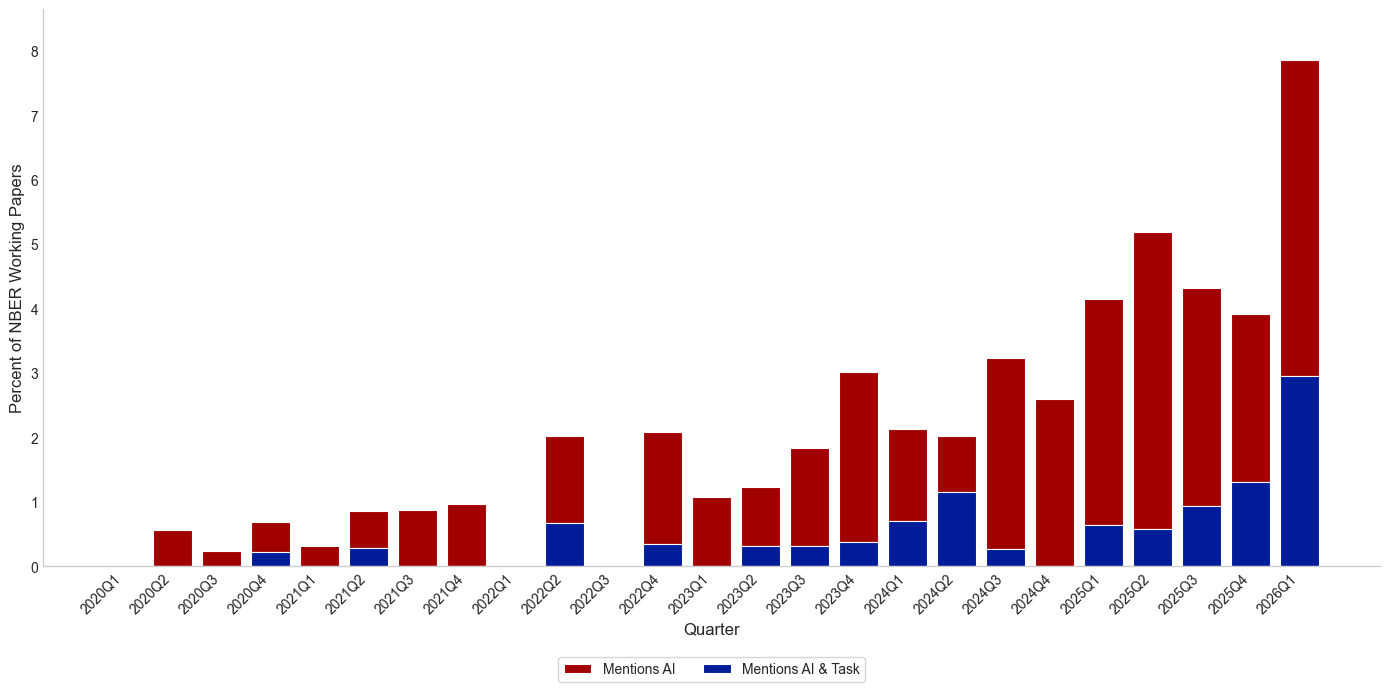

In [83]:
plt.style.use('seaborn-v0_8-whitegrid')

quarters = ai_quarterly.index.astype(str)
x = range(len(quarters))

task = task_quarterly['task_percent']
other_ai = (ai_quarterly['ai_percent'] - task).clip(lower=0)

fig, ax = plt.subplots(figsize=(14, 7))
ax.bar(x, other_ai, width=0.8, bottom=task, label='Mentions AI', color="#a10000", edgecolor='white', linewidth=0.8)
ax.bar(x, task, width=0.8, label='Mentions AI & Task', color="#001c99", edgecolor='white', linewidth=0.8)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=True)

ax.set_xlabel('Quarter', fontsize=12)
ax.set_ylabel('Percent of NBER Working Papers', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(quarters, rotation=45, ha='right')
ax.set_ylim(0, ai_quarterly['ai_percent'].max() * 1.1)
ax.grid(axis='x', visible=False)
ax.grid(axis='y', visible=False)
for spine in ax.spines.values():
    for spine_name, spine in ax.spines.items():
        if spine_name in ['top', 'right']:
            spine.set_visible(False)
plt.tight_layout()
plt.show()